In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Постановка проблемы

Предположим, к нам попали данные исследований нескольких (пусть n=3) вакцин;  
В каждом исследовании собирались данные о респондентах, с которых через 1 / 10 / 100 часов собирали оценку самочувствия  

In [2]:
respondents = 1000

def make_research():
  research = {
      "gender": np.random.randint(0,2,respondents),            # 0 - m, 1 - f
      "age": np.random.normal(25.0,20.0,respondents),
      "height": np.random.normal(170.0,15.5,respondents),
      "weight": np.random.normal(65.0,25.0,respondents)
      }

  feeled_bad = 0                                                # считаем, сколько всего людей ощутили себя плохо

  part = np.random.randint(7,20,1)                              # доля респондентов, которые будут подвержены плохому самочувствию
  feeled_bad += part

  research["condition_after_1"] = np.random.normal(
      (5 *                                                      # мат. ожидание сдвигается: если бы исследования и не было, в среднем все ставили бы ровно 5,
       (respondents * (1 - part/100)) +                         # но теперь 5 в среднем поставят меньшее число людей
       1 * (respondents * part/100))                            # остальные захотят поставить 1
      / respondents,

      2.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 7 else -1       # будем считать, что люди более склонны иметь ухудшившееся самочувствие через какое-то время
  part = np.random.randint(
      7 - (got_better * 2),
      20 - (got_better * 5),
      1)
  feeled_bad += part

  research["condition_after_10"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      1.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 3 else -1       # будем считать, что люди более склонны иметь улучшившееся самочувствие через продолжительное время
  part = np.random.randint(
      7 - (got_better * 3),
      20 - (got_better * 7),
      1)
  feeled_bad += part

  research["condition_after_100"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      2.5,
      respondents
      )

  return research

In [3]:
researh_0 = make_research()

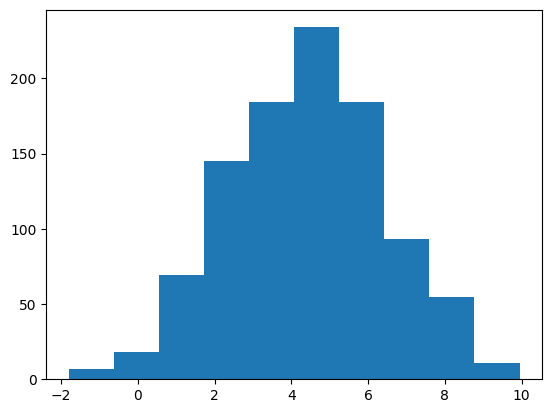

In [4]:
_ =plt.hist(researh_0["condition_after_1"])

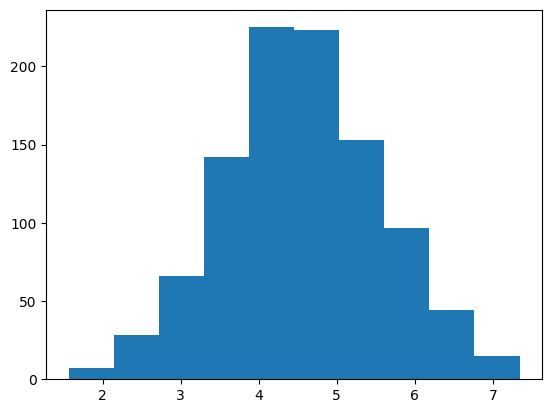

In [5]:
_ =plt.hist(researh_0["condition_after_10"])

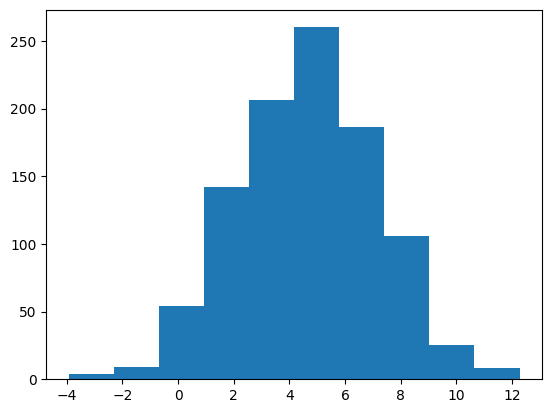

In [6]:
_ =plt.hist(researh_0["condition_after_100"])

# Задание

Мы хотим:
- проверить, что с данными все в порядке (т.к. данные генерили с помощью распределений, у нас могут быть отрицательные числа, которые надо исправить на 0, а также числа больше 10, которые надо исправить на 10) - построить гистограммы и почистить данные
- сравнить между собой результаты исследований разных вакцин и каким-либо образом представить сравнение исследований (т.е., к примеру, показать в одном пространстве сразу 3 исследования, пользуясь признаками "средняя оценка самочувствия после 1 часа", "средняя оценка самочувствия после 10 часов", "средняя оценка самочувствия после 100 часов"
- важно! обратите внимание на цвета, что вы используете

In [7]:
hours = [1, 10, 100]

for h in hours:
    data = researh_0[f"condition_after_{h}"]

    print(f"Через {h} часов:")
    print("Минимум:", data.min())
    print("Максимум:", data.max())
    print("Меньше 0:", np.sum(data < 0))
    print("Больше 10:", np.sum(data > 10))
    print()

Через 1 часов:
Минимум: -1.8039481156470432
Максимум: 9.945690736027498
Меньше 0: 13
Больше 10: 0

Через 10 часов:
Минимум: 1.563604111222248
Максимум: 7.343471885591793
Меньше 0: 0
Больше 10: 0

Через 100 часов:
Минимум: -3.9339115935988023
Максимум: 12.270477147236406
Меньше 0: 28
Больше 10: 14



In [11]:
a = np.array([-3, 2, 5, 9, 12])

np.clip(a, 0, 10)

for h in hours:
    key = f"condition_after_{h}"
    researh_0[key] = np.clip(researh_0[key], 0, 10)

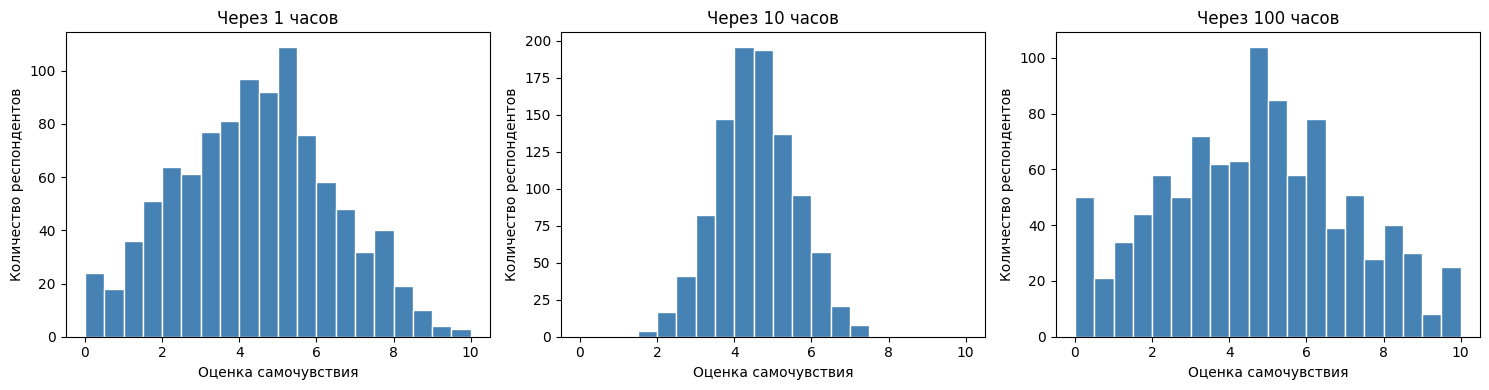

In [12]:
plt.figure(figsize=(15, 4))

for i, h in enumerate(hours):
    plt.subplot(1, 3, i + 1)

    plt.hist(researh_0[f"condition_after_{h}"],
             bins=20, range=(0, 10),
             color="steelblue", edgecolor="white")

    plt.title(f"Через {h} часов")
    plt.xlabel("Оценка самочувствия")
    plt.ylabel("Количество респондентов")

plt.tight_layout()
plt.show()

In [20]:
researh_0 = make_research()
researh_1 = make_research()
researh_2 = make_research()

researches = [researh_0, researh_1, researh_2]
hours = [1, 10, 100]

for research in researches:
    for h in hours:
        key = f"condition_after_{h}"
        research[key] = np.clip(research[key], 0, 10)

In [22]:
researches = [researh_0, researh_1, researh_2]
vaccine_names = ["Вакцина 1", "Вакцина 2", "Вакцина 3"]

mean_data = []

for name, research in zip(vaccine_names, researches):
    mean_data.append({
        "Вакцина": name,
        "Среднее через 1 час": np.mean(research["condition_after_1"]),
        "Среднее через 10 часов": np.mean(research["condition_after_10"]),
        "Среднее через 100 часов": np.mean(research["condition_after_100"])
    })

df_means = pd.DataFrame(mean_data)
df_means

,Вакцина,Среднее через 1 час,Среднее через 10 часов,Среднее через 100 часов
0,Вакцина 1,4.576216,4.639643,4.621866
1,Вакцина 2,4.312139,4.637056,4.722159
2,Вакцина 3,4.418189,4.137351,4.752593


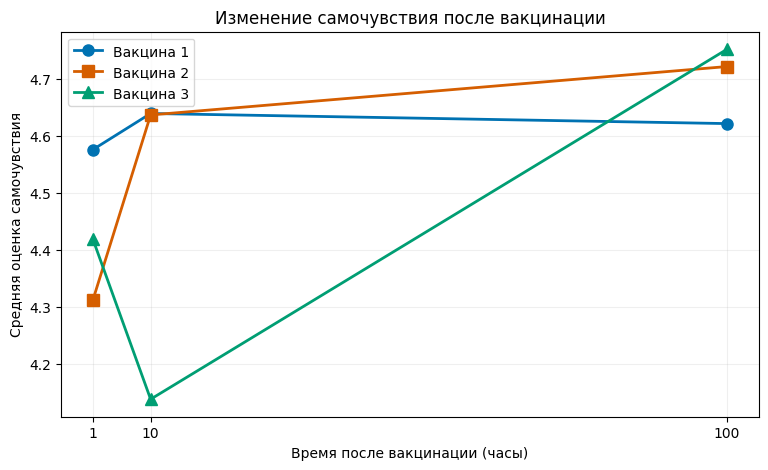

In [28]:
from mpl_toolkits.mplot3d import Axes3D

plt.figure(figsize=(9, 5))

times = [1, 10, 100]
columns = [
    "Среднее через 1 час",
    "Среднее через 10 часов",
    "Среднее через 100 часов"
]

for i in range(len(df_means)):
    values = df_means.loc[i, columns].values

    plt.plot(
        times, values,
        color=colors[i],
        marker=markers[i],
        linewidth=2,
        markersize=8,
        label=df_means.loc[i, "Вакцина"]
    )

plt.xlabel("Время после вакцинации (часы)")
plt.ylabel("Средняя оценка самочувствия")
plt.title("Изменение самочувствия после вакцинации")
plt.xticks(times)
plt.grid(alpha=0.2)
plt.legend()
plt.show()
